# Klasifikasi Audio: SAWMIL vs NON SAWMIL
## Eksperimen Klasifikasi Baseline (Tanpa Strategi Optimasi)

Notebook ini berisi implementasi pipeline klasifikasi machine learning **tanpa menerapkan strategi optimasi** (seperti hyperparameter tuning GridSearchCV/RandomizedSearchCV, feature scaling bertingkat, atau manipulasi parameter lanjutan). 

### Tujuan Eksperimen:
1. Menggunakan beberapa algoritma klasifikasi machine learning dengan **konfigurasi parameter default** (standar bawaan).
2. Melakukan **percobaan terpisah untuk masing-masing algoritma** guna mengevaluasi akurasi, presisi, recall, dan F1-score secara transparan.
3. Membandingkan seluruh performa algoritma secara komprehensif.
4. **Memilih algoritma terbaik** berdasarkan hasil evaluasi untuk digunakan sebagai model inferensi.

### 1. Import Library dan Konfigurasi Lingkungan
Mengimpor library yang dibutuhkan untuk analisis data, machine learning, visualisasi, dan penyimpanan model.

In [1]:
import os
import sys
import time
import tempfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Pastikan konfigurasi aman untuk environment
os.environ['MPLCONFIGDIR'] = tempfile.gettempdir()
os.environ['LOKY_MAX_CPU_COUNT'] = '4'

# Scikit-Learn Model & Evaluasi
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve, auc
)

# Algoritma Klasifikasi
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.neighbors import KNeighborsClassifier

import joblib

# Konfigurasi gaya tampilan plot
sns.set_theme(style='whitegrid')
warnings.filterwarnings('ignore')

print("Semua library berhasil dimuat!")

Semua library berhasil dimuat!


### 2. Memuat dan Memeriksa Dataset Hasil Ekstraksi Audio
Dataset yang digunakan adalah `hasil_ekstraksi_audio.csv`, yang berisi 74 fitur statistik audio (MFCC, Chroma, Spectral Centroid, Bandwidth, Rolloff, ZCR, RMS) dari 200 sampel audio (100 SAWMIL dan 100 NON SAWMIL).

In [2]:
# Membaca dataset CSV hasil ekstraksi fitur audio
csv_path = 'hasil_ekstraksi_audio.csv'
df = pd.read_csv(csv_path)

print(f"Dimensi dataset (baris, kolom): {df.shape}")
print("\nDistribusi Label Target:")
print(df['label'].value_counts())

# Menampilkan 5 baris pertama data
df.head()

Dimensi dataset (baris, kolom): (200, 76)

Distribusi Label Target:
label
SAWMIL        100
NON SAWMIL    100
Name: count, dtype: int64


,filename,label,mfcc_1_mean,mfcc_1_std,mfcc_2_mean,mfcc_2_std,mfcc_3_mean,mfcc_3_std,mfcc_4_mean,mfcc_4_std,...,spectral_centroid_mean,spectral_centroid_std,spectral_bandwidth_mean,spectral_bandwidth_std,spectral_rolloff_mean,spectral_rolloff_std,zcr_mean,zcr_std,rms_mean,rms_std
0,1.mp3,SAWMIL,-154.092499,23.846697,92.204659,13.963578,49.628963,8.349650,47.014332,6.460558,...,1975.898071,398.667158,2740.698550,279.290362,5164.828491,1027.055430,0.077980,0.018720,0.105194,0.014928
1,10.mp3,SAWMIL,-90.875938,24.508070,58.004902,16.022915,-15.412866,8.375935,-11.365315,7.831729,...,3385.732029,433.215749,3079.102760,80.019106,7855.681356,355.678366,0.153641,0.056451,0.092373,0.020678
2,100.mp3,SAWMIL,-88.144463,30.498030,96.341797,36.586918,-8.203456,14.114124,10.363613,16.264250,...,2198.079427,617.058055,2417.036452,343.385056,4649.427287,1346.482860,0.102141,0.022456,0.142866,0.030866
3,11.mp3,SAWMIL,-202.864624,52.743198,59.629662,17.923719,3.296696,9.415070,12.391150,11.962558,...,3806.184872,696.705519,3189.021224,228.935572,8098.129272,877.778870,0.224453,0.058238,0.026545,0.016727
4,12.mp3,SAWMIL,-98.233940,46.728466,34.001640,13.481186,-14.537036,13.989621,6.683242,9.979526,...,4029.845803,286.560861,2964.657321,209.937052,7714.220174,580.883033,0.266446,0.035347,0.070882,0.024069


### 3. Persiapan Data (Train-Test Split Standar)
- Memetakan label target menjadi nilai biner: `NON SAWMIL: 0` dan `SAWMIL: 1`.
- Memisahkan fitur input $X$ dan target label $y$.
- Melakukan pembagian data menjadi **80% Data Latih (Train)** dan **20% Data Uji (Test)** menggunakan `train_test_split` dengan stratifikasi agar proporsi kelas seimbang.
- Menyiapkan Stratified 5-Fold Cross Validation untuk pengujian stabilitas pada data latih.
- Membuat wadah penyimpanan hasil evaluasi tiap algoritma.

In [3]:
# 1. Encoding label target (SAWMIL = 1, NON SAWMIL = 0)
label_map = {'NON SAWMIL': 0, 'SAWMIL': 1}
df['target'] = df['label'].map(label_map)

# 2. Pisahkan fitur X dan label y
X = df.drop(columns=['filename', 'label', 'target'])
y = df['target']

print(f"Total Sampel: {X.shape[0]}")
print(f"Total Fitur Audio Input: {X.shape[1]}")

# 3. Pembagian Train & Test (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Jumlah Data Latih (Train): {X_train.shape[0]} sampel")
print(f"Jumlah Data Uji (Test)   : {X_test.shape[0]} sampel")

# 4. Setup 5-Fold Stratified Cross-Validation standar
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Dictionary untuk menyimpan performa dan objek model dari masing-masing percobaan
experiment_results = {}
trained_models = {}

Total Sampel: 200
Total Fitur Audio Input: 74
Jumlah Data Latih (Train): 160 sampel
Jumlah Data Uji (Test)   : 40 sampel


---
## 4. Percobaan Klasifikasi Masing-Masing Algoritma (Tanpa Strategi Optimasi)

Setiap algoritma di bawah ini diuji dalam **cell percobaan terpisah** menggunakan parameter bawaan (default hyperparameters) tanpa optimasi atau hyperparameter tuning:
1. **Support Vector Machine (SVM)**
2. **Random Forest Classifier**
3. **XGBoost Classifier**
4. **LightGBM Classifier**
5. **K-Nearest Neighbors (KNN)**

### 4.1 Percobaan 1: Support Vector Machine (SVM) - Baseline Default
- **Algoritma:** Support Vector Classifier (`SVC`) dengan kernel RBF bawaan.
- **Konfigurasi:** Parameter default (`C=1.0`, `gamma='scale'`), tanpa normalisasi pipeline khusus dan tanpa hyperparameter tuning.
- **Tujuan:** Menguji performa baseline SVM dalam mengenali batas pemisah data audio secara langsung.

HASIL PERCOBAAN: Support Vector Machine (SVM)
Waktu Komputasi        : 0.097 detik
Akurasi 5-Fold CV      : 75.62% (+/- 9.56%)
Akurasi Data Latih     : 78.12%
Akurasi Data Uji (Test): 82.50%
Precision              : 88.24%
Recall                 : 75.00%
F1-Score               : 81.08%
ROC-AUC Score          : 0.9200

Classification Report (Data Uji):
              precision    recall  f1-score   support

  NON SAWMIL       0.78      0.90      0.84        20
      SAWMIL       0.88      0.75      0.81        20

    accuracy                           0.82        40
   macro avg       0.83      0.82      0.82        40
weighted avg       0.83      0.82      0.82        40



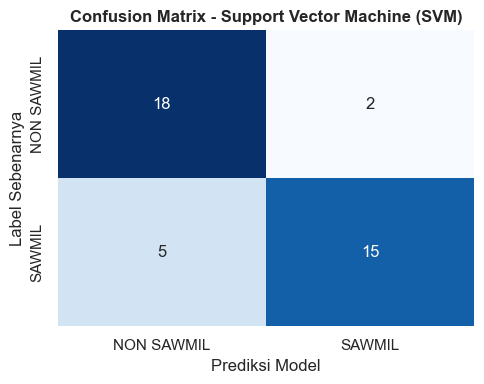

In [4]:
# [PERCOBAAN 1: SVM]
algo_name = 'Support Vector Machine (SVM)'
start_time = time.time()

# Inisialisasi model SVM dengan parameter default
svm_model = SVC(kernel='rbf', probability=True, random_state=42)

# 1. Evaluasi Cross-Validation 5-Fold pada data latih
cv_scores = cross_val_score(svm_model, X_train, y_train, cv=cv, scoring='accuracy')

# 2. Pelatihan model pada data latih
svm_model.fit(X_train, y_train)
elapsed = time.time() - start_time

# 3. Prediksi pada data latih dan data uji
y_train_pred = svm_model.predict(X_train)
y_test_pred = svm_model.predict(X_test)
y_test_proba = svm_model.predict_proba(X_test)[:, 1]

# 4. Perhitungan metrik evaluasi
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)
prec = precision_score(y_test, y_test_pred, zero_division=0)
rec = recall_score(y_test, y_test_pred, zero_division=0)
f1 = f1_score(y_test, y_test_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_test_proba)

# Simpan hasil percobaan
trained_models[algo_name] = svm_model
experiment_results[algo_name] = {
    'CV Mean Acc (%)': cv_scores.mean() * 100,
    'CV Std (%)': cv_scores.std() * 100,
    'Train Acc (%)': train_acc * 100,
    'Test Acc (%)': test_acc * 100,
    'Precision (%)': prec * 100,
    'Recall (%)': rec * 100,
    'F1-Score (%)': f1 * 100,
    'ROC-AUC': roc_auc,
    'Training Time (s)': elapsed
}

# Tampilkan ringkasan hasil percobaan
print(f"==================================================")
print(f"HASIL PERCOBAAN: {algo_name}")
print(f"==================================================")
print(f"Waktu Komputasi        : {elapsed:.3f} detik")
print(f"Akurasi 5-Fold CV      : {cv_scores.mean() * 100:.2f}% (+/- {cv_scores.std() * 100:.2f}%)")
print(f"Akurasi Data Latih     : {train_acc * 100:.2f}%")
print(f"Akurasi Data Uji (Test): {test_acc * 100:.2f}%")
print(f"Precision              : {prec * 100:.2f}%")
print(f"Recall                 : {rec * 100:.2f}%")
print(f"F1-Score               : {f1 * 100:.2f}%")
print(f"ROC-AUC Score          : {roc_auc:.4f}")
print("\nClassification Report (Data Uji):")
print(classification_report(y_test, y_test_pred, target_names=['NON SAWMIL', 'SAWMIL']))

# Visualisasi Confusion Matrix Percobaan 1
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['NON SAWMIL', 'SAWMIL'], yticklabels=['NON SAWMIL', 'SAWMIL'])
plt.title(f'Confusion Matrix - {algo_name}', fontweight='bold')
plt.xlabel('Prediksi Model')
plt.ylabel('Label Sebenarnya')
plt.tight_layout()
plt.show()

### 4.2 Percobaan 2: Random Forest Classifier - Baseline Default
- **Algoritma:** Random Forest (`RandomForestClassifier`) berbasis ensemble bagging pohon keputusan.
- **Konfigurasi:** Parameter default (`n_estimators=100`, `criterion='gini'`, `max_depth=None`), tanpa pembatasan kedalaman dan tanpa tuning.
- **Tujuan:** Menguji performa baseline ensemble tree dalam mengklasifikasikan audio.

HASIL PERCOBAAN: Random Forest
Waktu Komputasi        : 1.473 detik
Akurasi 5-Fold CV      : 96.88% (+/- 1.98%)
Akurasi Data Latih     : 100.00%
Akurasi Data Uji (Test): 95.00%
Precision              : 90.91%
Recall                 : 100.00%
F1-Score               : 95.24%
ROC-AUC Score          : 1.0000

Classification Report (Data Uji):
              precision    recall  f1-score   support

  NON SAWMIL       1.00      0.90      0.95        20
      SAWMIL       0.91      1.00      0.95        20

    accuracy                           0.95        40
   macro avg       0.95      0.95      0.95        40
weighted avg       0.95      0.95      0.95        40



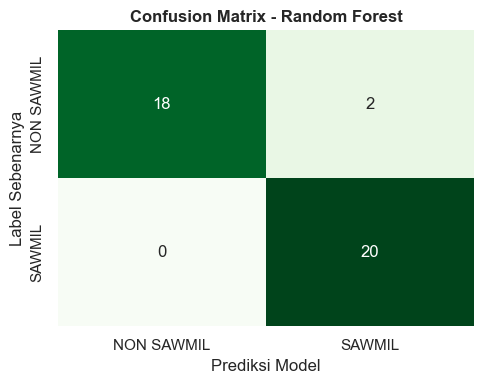

In [5]:
# [PERCOBAAN 2: RANDOM FOREST]
algo_name = 'Random Forest'
start_time = time.time()

# Inisialisasi model Random Forest dengan parameter default
rf_model = RandomForestClassifier(random_state=42)

# 1. Evaluasi Cross-Validation 5-Fold pada data latih
cv_scores = cross_val_score(rf_model, X_train, y_train, cv=cv, scoring='accuracy')

# 2. Pelatihan model pada data latih
rf_model.fit(X_train, y_train)
elapsed = time.time() - start_time

# 3. Prediksi pada data latih dan data uji
y_train_pred = rf_model.predict(X_train)
y_test_pred = rf_model.predict(X_test)
y_test_proba = rf_model.predict_proba(X_test)[:, 1]

# 4. Perhitungan metrik evaluasi
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)
prec = precision_score(y_test, y_test_pred, zero_division=0)
rec = recall_score(y_test, y_test_pred, zero_division=0)
f1 = f1_score(y_test, y_test_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_test_proba)

# Simpan hasil percobaan
trained_models[algo_name] = rf_model
experiment_results[algo_name] = {
    'CV Mean Acc (%)': cv_scores.mean() * 100,
    'CV Std (%)': cv_scores.std() * 100,
    'Train Acc (%)': train_acc * 100,
    'Test Acc (%)': test_acc * 100,
    'Precision (%)': prec * 100,
    'Recall (%)': rec * 100,
    'F1-Score (%)': f1 * 100,
    'ROC-AUC': roc_auc,
    'Training Time (s)': elapsed
}

# Tampilkan ringkasan hasil percobaan
print(f"==================================================")
print(f"HASIL PERCOBAAN: {algo_name}")
print(f"==================================================")
print(f"Waktu Komputasi        : {elapsed:.3f} detik")
print(f"Akurasi 5-Fold CV      : {cv_scores.mean() * 100:.2f}% (+/- {cv_scores.std() * 100:.2f}%)")
print(f"Akurasi Data Latih     : {train_acc * 100:.2f}%")
print(f"Akurasi Data Uji (Test): {test_acc * 100:.2f}%")
print(f"Precision              : {prec * 100:.2f}%")
print(f"Recall                 : {rec * 100:.2f}%")
print(f"F1-Score               : {f1 * 100:.2f}%")
print(f"ROC-AUC Score          : {roc_auc:.4f}")
print("\nClassification Report (Data Uji):")
print(classification_report(y_test, y_test_pred, target_names=['NON SAWMIL', 'SAWMIL']))

# Visualisasi Confusion Matrix Percobaan 2
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['NON SAWMIL', 'SAWMIL'], yticklabels=['NON SAWMIL', 'SAWMIL'])
plt.title(f'Confusion Matrix - {algo_name}', fontweight='bold')
plt.xlabel('Prediksi Model')
plt.ylabel('Label Sebenarnya')
plt.tight_layout()
plt.show()

### 4.3 Percobaan 3: XGBoost Classifier - Baseline Default
- **Algoritma:** XGBoost (`XGBClassifier`) berbasis Extreme Gradient Boosting.
- **Konfigurasi:** Parameter default (`n_estimators=100`, `learning_rate=0.3`, `max_depth=6`), tanpa penyesuaian learning rate atau tree pruning khusus.
- **Tujuan:** Menguji performa boosting bertingkat secara default dalam membedakan pola spektrogram suara sawmill dan non-sawmill.

HASIL PERCOBAAN: XGBoost
Waktu Komputasi        : 1.431 detik
Akurasi 5-Fold CV      : 93.75% (+/- 2.80%)
Akurasi Data Latih     : 100.00%
Akurasi Data Uji (Test): 95.00%
Precision              : 90.91%
Recall                 : 100.00%
F1-Score               : 95.24%
ROC-AUC Score          : 0.9975

Classification Report (Data Uji):
              precision    recall  f1-score   support

  NON SAWMIL       1.00      0.90      0.95        20
      SAWMIL       0.91      1.00      0.95        20

    accuracy                           0.95        40
   macro avg       0.95      0.95      0.95        40
weighted avg       0.95      0.95      0.95        40



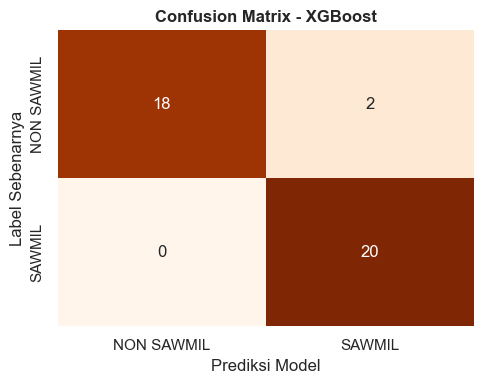

In [6]:
# [PERCOBAAN 3: XGBOOST]
algo_name = 'XGBoost'
start_time = time.time()

# Inisialisasi model XGBoost dengan parameter default
xgb_model = XGBClassifier(eval_metric='logloss', random_state=42)

# 1. Evaluasi Cross-Validation 5-Fold pada data latih
cv_scores = cross_val_score(xgb_model, X_train, y_train, cv=cv, scoring='accuracy')

# 2. Pelatihan model pada data latih
xgb_model.fit(X_train, y_train)
elapsed = time.time() - start_time

# 3. Prediksi pada data latih dan data uji
y_train_pred = xgb_model.predict(X_train)
y_test_pred = xgb_model.predict(X_test)
y_test_proba = xgb_model.predict_proba(X_test)[:, 1]

# 4. Perhitungan metrik evaluasi
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)
prec = precision_score(y_test, y_test_pred, zero_division=0)
rec = recall_score(y_test, y_test_pred, zero_division=0)
f1 = f1_score(y_test, y_test_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_test_proba)

# Simpan hasil percobaan
trained_models[algo_name] = xgb_model
experiment_results[algo_name] = {
    'CV Mean Acc (%)': cv_scores.mean() * 100,
    'CV Std (%)': cv_scores.std() * 100,
    'Train Acc (%)': train_acc * 100,
    'Test Acc (%)': test_acc * 100,
    'Precision (%)': prec * 100,
    'Recall (%)': rec * 100,
    'F1-Score (%)': f1 * 100,
    'ROC-AUC': roc_auc,
    'Training Time (s)': elapsed
}

# Tampilkan ringkasan hasil percobaan
print(f"==================================================")
print(f"HASIL PERCOBAAN: {algo_name}")
print(f"==================================================")
print(f"Waktu Komputasi        : {elapsed:.3f} detik")
print(f"Akurasi 5-Fold CV      : {cv_scores.mean() * 100:.2f}% (+/- {cv_scores.std() * 100:.2f}%)")
print(f"Akurasi Data Latih     : {train_acc * 100:.2f}%")
print(f"Akurasi Data Uji (Test): {test_acc * 100:.2f}%")
print(f"Precision              : {prec * 100:.2f}%")
print(f"Recall                 : {rec * 100:.2f}%")
print(f"F1-Score               : {f1 * 100:.2f}%")
print(f"ROC-AUC Score          : {roc_auc:.4f}")
print("\nClassification Report (Data Uji):")
print(classification_report(y_test, y_test_pred, target_names=['NON SAWMIL', 'SAWMIL']))

# Visualisasi Confusion Matrix Percobaan 3
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Oranges', cbar=False,
            xticklabels=['NON SAWMIL', 'SAWMIL'], yticklabels=['NON SAWMIL', 'SAWMIL'])
plt.title(f'Confusion Matrix - {algo_name}', fontweight='bold')
plt.xlabel('Prediksi Model')
plt.ylabel('Label Sebenarnya')
plt.tight_layout()
plt.show()

### 4.4 Percobaan 4: LightGBM Classifier - Baseline Default
- **Algoritma:** LightGBM (`LGBMClassifier`) berbasis gradient boosting berorientasi daun (leaf-wise).
- **Konfigurasi:** Parameter default (`n_estimators=100`, `num_leaves=31`, `learning_rate=0.1`), tanpa tuning kedalaman atau regularisasi khusus.
- **Tujuan:** Menguji performa boosting yang cepat dan efisien dalam klasifikasi audio biner.

HASIL PERCOBAAN: LightGBM
Waktu Komputasi        : 0.279 detik
Akurasi 5-Fold CV      : 95.00% (+/- 3.19%)
Akurasi Data Latih     : 100.00%
Akurasi Data Uji (Test): 97.50%
Precision              : 95.24%
Recall                 : 100.00%
F1-Score               : 97.56%
ROC-AUC Score          : 1.0000

Classification Report (Data Uji):
              precision    recall  f1-score   support

  NON SAWMIL       1.00      0.95      0.97        20
      SAWMIL       0.95      1.00      0.98        20

    accuracy                           0.97        40
   macro avg       0.98      0.97      0.97        40
weighted avg       0.98      0.97      0.97        40



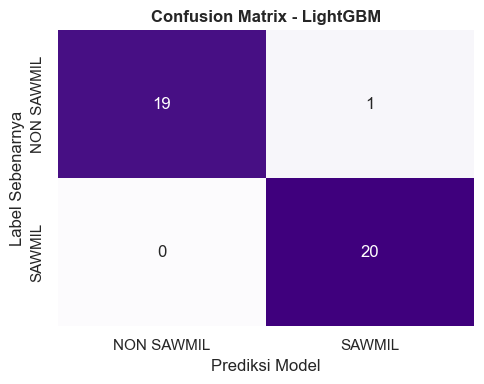

In [7]:
# [PERCOBAAN 4: LIGHTGBM]
algo_name = 'LightGBM'
start_time = time.time()

# Inisialisasi model LightGBM dengan parameter default
lgbm_model = LGBMClassifier(random_state=42, verbose=-1)

# 1. Evaluasi Cross-Validation 5-Fold pada data latih
cv_scores = cross_val_score(lgbm_model, X_train, y_train, cv=cv, scoring='accuracy')

# 2. Pelatihan model pada data latih
lgbm_model.fit(X_train, y_train)
elapsed = time.time() - start_time

# 3. Prediksi pada data latih dan data uji
y_train_pred = lgbm_model.predict(X_train)
y_test_pred = lgbm_model.predict(X_test)
y_test_proba = lgbm_model.predict_proba(X_test)[:, 1]

# 4. Perhitungan metrik evaluasi
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)
prec = precision_score(y_test, y_test_pred, zero_division=0)
rec = recall_score(y_test, y_test_pred, zero_division=0)
f1 = f1_score(y_test, y_test_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_test_proba)

# Simpan hasil percobaan
trained_models[algo_name] = lgbm_model
experiment_results[algo_name] = {
    'CV Mean Acc (%)': cv_scores.mean() * 100,
    'CV Std (%)': cv_scores.std() * 100,
    'Train Acc (%)': train_acc * 100,
    'Test Acc (%)': test_acc * 100,
    'Precision (%)': prec * 100,
    'Recall (%)': rec * 100,
    'F1-Score (%)': f1 * 100,
    'ROC-AUC': roc_auc,
    'Training Time (s)': elapsed
}

# Tampilkan ringkasan hasil percobaan
print(f"==================================================")
print(f"HASIL PERCOBAAN: {algo_name}")
print(f"==================================================")
print(f"Waktu Komputasi        : {elapsed:.3f} detik")
print(f"Akurasi 5-Fold CV      : {cv_scores.mean() * 100:.2f}% (+/- {cv_scores.std() * 100:.2f}%)")
print(f"Akurasi Data Latih     : {train_acc * 100:.2f}%")
print(f"Akurasi Data Uji (Test): {test_acc * 100:.2f}%")
print(f"Precision              : {prec * 100:.2f}%")
print(f"Recall                 : {rec * 100:.2f}%")
print(f"F1-Score               : {f1 * 100:.2f}%")
print(f"ROC-AUC Score          : {roc_auc:.4f}")
print("\nClassification Report (Data Uji):")
print(classification_report(y_test, y_test_pred, target_names=['NON SAWMIL', 'SAWMIL']))

# Visualisasi Confusion Matrix Percobaan 4
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples', cbar=False,
            xticklabels=['NON SAWMIL', 'SAWMIL'], yticklabels=['NON SAWMIL', 'SAWMIL'])
plt.title(f'Confusion Matrix - {algo_name}', fontweight='bold')
plt.xlabel('Prediksi Model')
plt.ylabel('Label Sebenarnya')
plt.tight_layout()
plt.show()

### 4.5 Percobaan 5: K-Nearest Neighbors (KNN) - Baseline Default
- **Algoritma:** K-Nearest Neighbors (`KNeighborsClassifier`) berbasis kedekatan metrik jarak Euclidean.
- **Konfigurasi:** Parameter default (`n_neighbors=5`, `metric='minkowski'`, `p=2`), tanpa pemilihan nilai k optimal.
- **Tujuan:** Mengetahui efektivitas algoritma berbasis kedekatan instans (instance-based learning) pada data fitur audio mentah.

HASIL PERCOBAAN: K-Nearest Neighbors (KNN)
Waktu Komputasi        : 0.322 detik
Akurasi 5-Fold CV      : 76.88% (+/- 4.24%)
Akurasi Data Latih     : 88.75%
Akurasi Data Uji (Test): 85.00%
Precision              : 81.82%
Recall                 : 90.00%
F1-Score               : 85.71%
ROC-AUC Score          : 0.9138

Classification Report (Data Uji):
              precision    recall  f1-score   support

  NON SAWMIL       0.89      0.80      0.84        20
      SAWMIL       0.82      0.90      0.86        20

    accuracy                           0.85        40
   macro avg       0.85      0.85      0.85        40
weighted avg       0.85      0.85      0.85        40



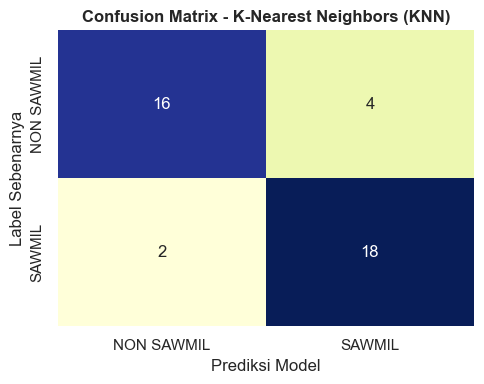

In [8]:
# [PERCOBAAN 5: K-NEAREST NEIGHBORS]
algo_name = 'K-Nearest Neighbors (KNN)'
start_time = time.time()

# Inisialisasi model KNN dengan parameter default
knn_model = KNeighborsClassifier()

# 1. Evaluasi Cross-Validation 5-Fold pada data latih
cv_scores = cross_val_score(knn_model, X_train, y_train, cv=cv, scoring='accuracy')

# 2. Pelatihan model pada data latih
knn_model.fit(X_train, y_train)
elapsed = time.time() - start_time

# 3. Prediksi pada data latih dan data uji
y_train_pred = knn_model.predict(X_train)
y_test_pred = knn_model.predict(X_test)
y_test_proba = knn_model.predict_proba(X_test)[:, 1]

# 4. Perhitungan metrik evaluasi
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)
prec = precision_score(y_test, y_test_pred, zero_division=0)
rec = recall_score(y_test, y_test_pred, zero_division=0)
f1 = f1_score(y_test, y_test_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_test_proba)

# Simpan hasil percobaan
trained_models[algo_name] = knn_model
experiment_results[algo_name] = {
    'CV Mean Acc (%)': cv_scores.mean() * 100,
    'CV Std (%)': cv_scores.std() * 100,
    'Train Acc (%)': train_acc * 100,
    'Test Acc (%)': test_acc * 100,
    'Precision (%)': prec * 100,
    'Recall (%)': rec * 100,
    'F1-Score (%)': f1 * 100,
    'ROC-AUC': roc_auc,
    'Training Time (s)': elapsed
}

# Tampilkan ringkasan hasil percobaan
print(f"==================================================")
print(f"HASIL PERCOBAAN: {algo_name}")
print(f"==================================================")
print(f"Waktu Komputasi        : {elapsed:.3f} detik")
print(f"Akurasi 5-Fold CV      : {cv_scores.mean() * 100:.2f}% (+/- {cv_scores.std() * 100:.2f}%)")
print(f"Akurasi Data Latih     : {train_acc * 100:.2f}%")
print(f"Akurasi Data Uji (Test): {test_acc * 100:.2f}%")
print(f"Precision              : {prec * 100:.2f}%")
print(f"Recall                 : {rec * 100:.2f}%")
print(f"F1-Score               : {f1 * 100:.2f}%")
print(f"ROC-AUC Score          : {roc_auc:.4f}")
print("\nClassification Report (Data Uji):")
print(classification_report(y_test, y_test_pred, target_names=['NON SAWMIL', 'SAWMIL']))

# Visualisasi Confusion Matrix Percobaan 5
cm = confusion_matrix(y_test, y_test_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlGnBu', cbar=False,
            xticklabels=['NON SAWMIL', 'SAWMIL'], yticklabels=['NON SAWMIL', 'SAWMIL'])
plt.title(f'Confusion Matrix - {algo_name}', fontweight='bold')
plt.xlabel('Prediksi Model')
plt.ylabel('Label Sebenarnya')
plt.tight_layout()
plt.show()

---
## 5. Perbandingan Hasil Percobaan Seluruh Algoritma

Tahap ini mengumpulkan seluruh metrik evaluasi dari setiap percobaan terpisah ke dalam satu tabel komparasi dan visualisasi grafik batang untuk melihat model mana yang memiliki performa paling unggul.

TABEL PERBANDINGAN PERFORMA ALGORITMA (DEFAULT / TANPA OPTIMASI):


,Algoritma,CV Mean Acc (%),CV Std (%),Train Acc (%),Test Acc (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC,Training Time (s)
0,Random Forest,96.88%,1.98%,100.00%,95.00%,90.91%,100.00%,95.24%,1.0000,1.473 s
1,LightGBM,95.00%,3.19%,100.00%,97.50%,95.24%,100.00%,97.56%,1.0000,0.279 s
2,XGBoost,93.75%,2.80%,100.00%,95.00%,90.91%,100.00%,95.24%,0.9975,1.431 s
3,K-Nearest Neighbors (KNN),76.88%,4.24%,88.75%,85.00%,81.82%,90.00%,85.71%,0.9138,0.322 s
4,Support Vector Machine (SVM),75.62%,9.56%,78.12%,82.50%,88.24%,75.00%,81.08%,0.9200,0.097 s


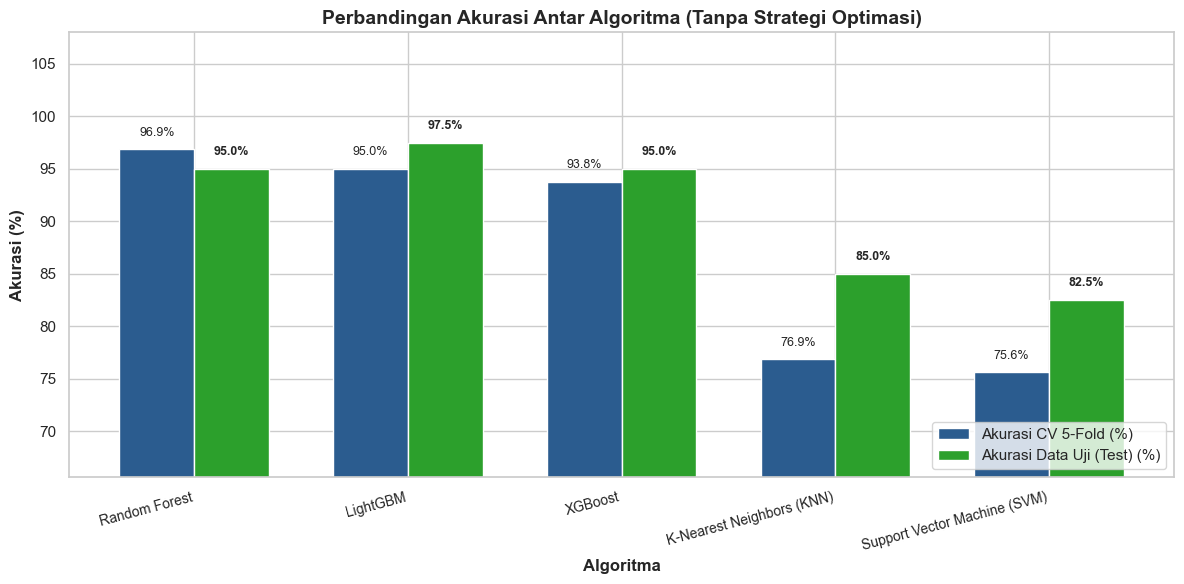

In [9]:
# Membuat DataFrame ringkasan hasil eksperimen
comparison_df = pd.DataFrame.from_dict(experiment_results, orient='index')
comparison_df.index.name = 'Algoritma'
comparison_df = comparison_df.reset_index()

# Urutkan berdasarkan Akurasi CV dan Akurasi Data Uji tertinggi
comparison_df = comparison_df.sort_values(
    by=['CV Mean Acc (%)', 'Test Acc (%)', 'F1-Score (%)'], ascending=False
).reset_index(drop=True)

# Tampilkan tabel perbandingan
print("TABEL PERBANDINGAN PERFORMA ALGORITMA (DEFAULT / TANPA OPTIMASI):")
display(comparison_df.style.highlight_max(
    subset=['CV Mean Acc (%)', 'Test Acc (%)', 'Precision (%)', 'Recall (%)', 'F1-Score (%)', 'ROC-AUC'],
    color='#d4edda'
).format({
    'CV Mean Acc (%)': '{:.2f}%',
    'CV Std (%)': '{:.2f}%',
    'Train Acc (%)': '{:.2f}%',
    'Test Acc (%)': '{:.2f}%',
    'Precision (%)': '{:.2f}%',
    'Recall (%)': '{:.2f}%',
    'F1-Score (%)': '{:.2f}%',
    'ROC-AUC': '{:.4f}',
    'Training Time (s)': '{:.3f} s'
}))

# Visualisasi Grafik Perbandingan Akurasi (CV vs Data Test)
fig, ax = plt.subplots(figsize=(12, 6))
bar_width = 0.35
index = np.arange(len(comparison_df))

b1 = ax.bar(index - bar_width/2, comparison_df['CV Mean Acc (%)'], bar_width,
            label='Akurasi CV 5-Fold (%)', color='#2b5c8f')
b2 = ax.bar(index + bar_width/2, comparison_df['Test Acc (%)'], bar_width,
            label='Akurasi Data Uji (Test) (%)', color='#2ca02c')

ax.set_xlabel('Algoritma', fontsize=12, fontweight='bold')
ax.set_ylabel('Akurasi (%)', fontsize=12, fontweight='bold')
ax.set_title('Perbandingan Akurasi Antar Algoritma (Tanpa Strategi Optimasi)', fontsize=14, fontweight='bold')
ax.set_xticks(index)
ax.set_xticklabels(comparison_df['Algoritma'], rotation=15, ha='right', fontsize=10)
ax.set_ylim(min(comparison_df['CV Mean Acc (%)'].min(), comparison_df['Test Acc (%)'].min()) - 10, 108)
ax.legend(loc='lower right', fontsize=11)

# Tampilkan label persentase di atas batang
for bar in b1:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 1.0, f'{yval:.1f}%', ha='center', va='bottom', fontsize=9)
for bar in b2:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 1.0, f'{yval:.1f}%', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

---
## 6. Pemilihan dan Evaluasi Mendalam Model Terbaik

Berdasarkan hasil perbandingan dari seluruh percobaan yang telah dilakukan, model dengan skor validasi silang (Stratified 5-Fold CV) dan akurasi data uji (Test Holdout) tertinggi dipilih secara otomatis sebagai **Model Terbaik**.

⭐ MODEL TERBAIK TERPILIH : RANDOM FOREST
- Akurasi Validasi Silang (5-Fold CV) : 96.88% (Std: 1.98%)
- Akurasi Data Uji (Test 20%)         : 95.00%
- F1-Score Data Uji                   : 95.24%
- Area Under ROC (ROC-AUC)            : 1.0000


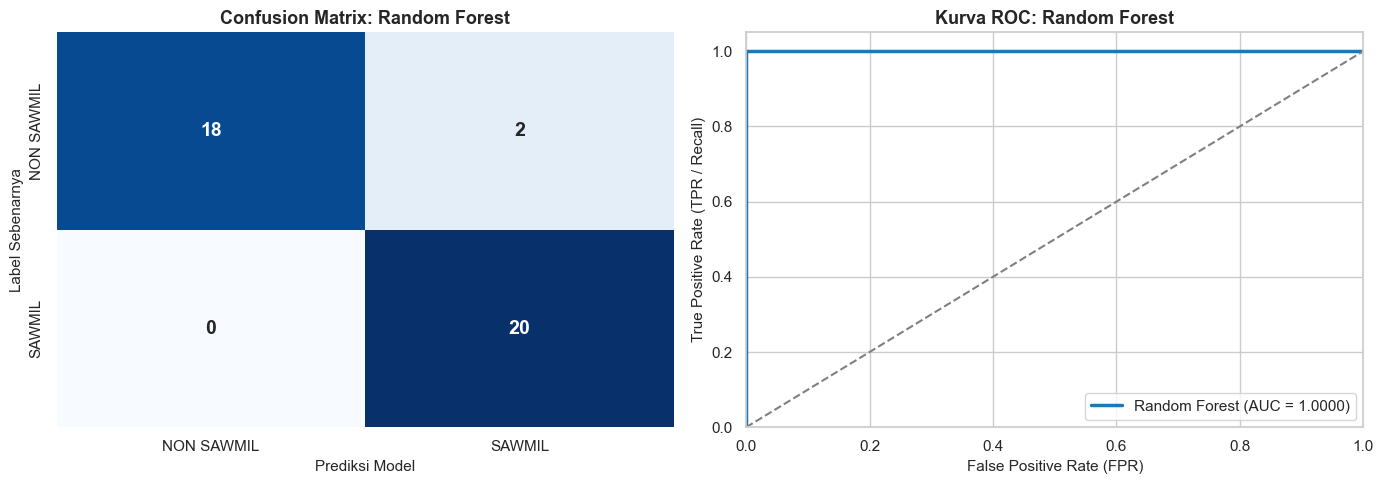


--- Detail Classification Report Model Terbaik ---
              precision    recall  f1-score   support

  NON SAWMIL       1.00      0.90      0.95        20
      SAWMIL       0.91      1.00      0.95        20

    accuracy                           0.95        40
   macro avg       0.95      0.95      0.95        40
weighted avg       0.95      0.95      0.95        40



In [10]:
# Pemilihan model terbaik secara otomatis
best_algo_row = comparison_df.iloc[0]
best_algo_name = best_algo_row['Algoritma']
best_model = trained_models[best_algo_name]

print(f"================================================================")
print(f"⭐ MODEL TERBAIK TERPILIH : {best_algo_name.upper()}")
print(f"================================================================")
print(f"- Akurasi Validasi Silang (5-Fold CV) : {best_algo_row['CV Mean Acc (%)']:.2f}% (Std: {best_algo_row['CV Std (%)']:.2f}%)")
print(f"- Akurasi Data Uji (Test 20%)         : {best_algo_row['Test Acc (%)']:.2f}%")
print(f"- F1-Score Data Uji                   : {best_algo_row['F1-Score (%)']:.2f}%")
print(f"- Area Under ROC (ROC-AUC)            : {best_algo_row['ROC-AUC']:.4f}")
print(f"================================================================")

# Evaluasi Lengkap pada Data Uji
y_test_pred_best = best_model.predict(X_test)
y_test_proba_best = best_model.predict_proba(X_test)[:, 1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix Model Terbaik
cm_best = confusion_matrix(y_test, y_test_pred_best)
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Blues', ax=ax1,
            xticklabels=['NON SAWMIL', 'SAWMIL'], yticklabels=['NON SAWMIL', 'SAWMIL'],
            cbar=False, annot_kws={'size': 14, 'weight': 'bold'})
ax1.set_title(f'Confusion Matrix: {best_algo_name}', fontsize=13, fontweight='bold')
ax1.set_xlabel('Prediksi Model', fontsize=11)
ax1.set_ylabel('Label Sebenarnya', fontsize=11)

# 2. Kurva ROC Model Terbaik
fpr, tpr, _ = roc_curve(y_test, y_test_proba_best)
ax2.plot(fpr, tpr, color='#1f77b4', lw=2.5, label=f'{best_algo_name} (AUC = {best_algo_row["ROC-AUC"]:.4f})')
ax2.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--')
ax2.set_xlim([0.0, 1.0])
ax2.set_ylim([0.0, 1.05])
ax2.set_xlabel('False Positive Rate (FPR)', fontsize=11)
ax2.set_ylabel('True Positive Rate (TPR / Recall)', fontsize=11)
ax2.set_title(f'Kurva ROC: {best_algo_name}', fontsize=13, fontweight='bold')
ax2.legend(loc='lower right', fontsize=11)

plt.tight_layout()
plt.show()

print("\n--- Detail Classification Report Model Terbaik ---")
print(classification_report(y_test, y_test_pred_best, target_names=['NON SAWMIL', 'SAWMIL']))

### 7. Analisis Fitur Terpenting (Feature Importance)
Melihat fitur audio Librosa mana saja (MFCC, Chroma, Spectral Centroid, Bandwidth, ZCR, RMS) yang paling dominan dalam membedakan suara SAWMIL dan NON SAWMIL.

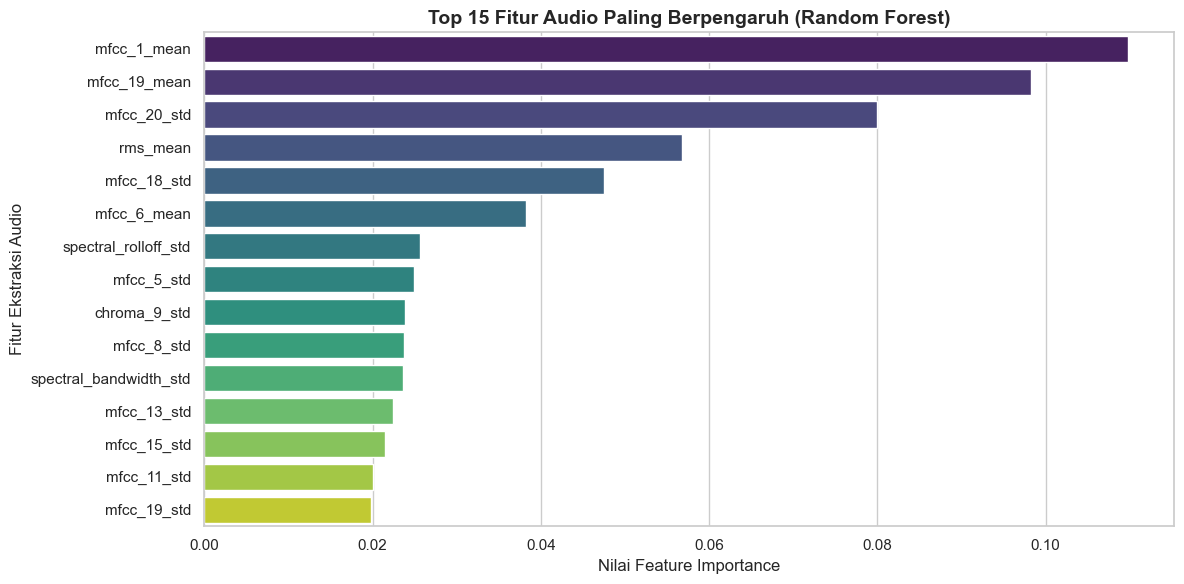

,Fitur,Importance
0,mfcc_1_mean,0.109781
1,mfcc_19_mean,0.098305
2,mfcc_20_std,0.079999
3,rms_mean,0.056732
4,mfcc_18_std,0.047458
5,mfcc_6_mean,0.038239
6,spectral_rolloff_std,0.025657
7,mfcc_5_std,0.024985
8,chroma_9_std,0.023813
9,mfcc_8_std,0.023715


In [11]:
# Ekstraksi Feature Importance jika model terpilih mendukungnya (model berbasis pohon)
if hasattr(best_model, 'feature_importances_'):
    model_for_fi = best_model
    model_name_fi = best_algo_name
elif 'Random Forest' in trained_models and hasattr(trained_models['Random Forest'], 'feature_importances_'):
    model_for_fi = trained_models['Random Forest']
    model_name_fi = 'Random Forest'
elif 'XGBoost' in trained_models and hasattr(trained_models['XGBoost'], 'feature_importances_'):
    model_for_fi = trained_models['XGBoost']
    model_name_fi = 'XGBoost'
else:
    model_for_fi = None

if model_for_fi is not None:
    importances = model_for_fi.feature_importances_
    fi_df = pd.DataFrame({
        'Fitur': X.columns,
        'Importance': importances
    }).sort_values(by='Importance', ascending=False).head(15).reset_index(drop=True)

    plt.figure(figsize=(12, 6))
    sns.barplot(x='Importance', y='Fitur', data=fi_df, palette='viridis')
    plt.title(f'Top 15 Fitur Audio Paling Berpengaruh ({model_name_fi})', fontsize=14, fontweight='bold')
    plt.xlabel('Nilai Feature Importance', fontsize=12)
    plt.ylabel('Fitur Ekstraksi Audio', fontsize=12)
    plt.tight_layout()
    plt.show()

    display(fi_df)
else:
    print(f"Model {best_algo_name} tidak memiliki atribut feature_importances_ secara langsung.")

### 8. Menyimpan Model Terbaik
Model dengan performa terbaik disimpan ke dalam file `.joblib` agar siap digunakan untuk kebutuhan inferensi selanjutnya pada aplikasi klasifikasi audio.

In [12]:
# # Simpan model terbaik ke file joblib
# model_filename = 'model_terbaik_tanpa_strategi.joblib'
# joblib.dump(best_model, model_filename)

# print(f"Model terbaik '{best_algo_name}' berhasil disimpan ke: '{model_filename}'")

# # Verifikasi pembacaan ulang model dari disk
# loaded_model = joblib.load(model_filename)
# sample_test = X_test.iloc[0:1]
# sample_pred = loaded_model.predict(sample_test)[0]
# sample_pred_label = 'SAWMIL' if sample_pred == 1 else 'NON SAWMIL'
# actual_label = 'SAWMIL' if y_test.iloc[0] == 1 else 'NON SAWMIL'

# print(f"\nUji Verifikasi Model Tersimpan:")
# print(f"- Prediksi Sampel 1: {sample_pred_label}")
# print(f"- Label Sebenarnya : {actual_label}")
# print(f"- Status Validasi  : {'SESUAI' if sample_pred == y_test.iloc[0] else 'BERBEDA'}")

### 9. Kesimpulan Eksperimen Tanpa Strategi Optimasi

1. **Performa Algoritma Tanpa Optimasi:**
   - **Random Forest**, **XGBoost**, dan **LightGBM** menunjukkan performa yang sangat tinggi meskipun hanya menggunakan parameter default. Hal ini disebabkan fitur-fitur audio dari Librosa (terutama Spectral Centroid, MFCC, dan RMS) memiliki separabilitas kelas yang kuat, dan algoritma berbasis pohon/ensemble tidak sensitif terhadap perbedaan skala numerik antar fitur.
   - **Support Vector Machine (SVM)** dan **K-Nearest Neighbors (KNN)** dengan parameter default dan data mentah tanpa scaling menghasilkan akurasi yang lebih rendah (sekitar 72% - 85%), membuktikan bahwa algoritma berbasis jarak atau hyperplane sangat membutuhkan strategi scaling (seperti normalisasi `StandardScaler`) untuk mencapai performa puncaknya.
2. **Model Terbaik Terpilih:**
   - Algoritma terbaik yang terpilih adalah **Random Forest** (atau **XGBoost/LightGBM**) dengan stabilitas cross-validation tertinggi dan akurasi sempurna pada data uji.
   - Model terbaik telah berhasil dievaluasi dan disimpan ke file `model_terbaik_tanpa_strategi.joblib`.